# Stage 4 (Week 1): Full 10-Seed Data Poisoning Attack Experiment & Analysis

**Objective:** Analyze the complete 10-seed poisoning benchmark (`results/attack_results.csv`, 270 runs across seeds 0–9) under the frozen Stage 3/4 protocol. Following our continuing methodological rules, this notebook reads the saved raw result file directly without rerunning experiments invisibly, aggregates every condition using the cross-seed **Mean and Sample Standard Deviation ($\pm 1\ \text{Std}$)**, generates publication-ready figures and representative confusion matrices at $0\%, 10\%,$ and $20\%$ poisoning, and separates **direct empirical observations** from **possible mechanistic explanations**.

## 1. Completion Check & Integrity Audit of `results/attack_results.csv`
Before interpreting any metric trends, we verify that `results/attack_results.csv` contains all **270 expected rows**:
- **30 Clean-Baseline Rows:** $10\text{ seeds } (0\text{–}9) \times 1\text{ clean rate } (0\%) \times 3\text{ models}$
- **240 Poisoned-Condition Rows:** $10\text{ seeds } (0\text{–}9) \times 2\text{ attacks } (\text{random, targeted}) \times 4\text{ nonzero rates } (1\%, 5\%, 10\%, 20\%) \times 3\text{ models}$

In [1]:
# Cell 1: Load saved results/attack_results.csv and verify completion invariants
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath('..'))
from src.experiments import aggregate_attack_results
from src.visualization import (
    plot_pilot_learning_curves,
    plot_pilot_multi_metric_grid,
    plot_random_vs_targeted_degradation,
    plot_representative_confusion_matrices_grid,
    plot_seed_crossover_distributions,
)

plt.rcParams['figure.dpi'] = 120

csv_path = '../results/attack_results.csv'
attack_df = pd.read_csv(csv_path)

n_total = len(attack_df)
n_clean = len(attack_df[attack_df['attack'] == 'clean'])
n_poisoned = len(attack_df[attack_df['attack'] != 'clean'])
n_missing = int(attack_df.isnull().sum().sum())

assert n_total == 270, f'Expected 270 rows, found {n_total}'
assert n_clean == 30, f'Expected 30 clean rows, found {n_clean}'
assert n_poisoned == 240, f'Expected 240 poisoned rows, found {n_poisoned}'
assert n_missing == 0, f'Expected 0 NaN values, found {n_missing}'

expected_counts = {0.0: 0, 0.01: 37, 0.05: 184, 0.10: 368, 0.20: 736}
for rate, exp_cnt in expected_counts.items():
    obs = attack_df[np.isclose(attack_df['poison_rate'], rate)]['n_poisoned'].unique()
    assert len(obs) == 1 and int(obs[0]) == exp_cnt

print('=== STAGE 4 FULL ATTACK DATASET AUDIT (results/attack_results.csv) ===')
print(f'Total rows:              {n_total} (Expected: 270)')
print(f'Clean-baseline rows:     {n_clean} (Expected: 30 = 10 seeds x 3 models)')
print(f'Poisoned-condition rows: {n_poisoned} (Expected: 240 = 10 seeds x 2 attacks x 4 rates x 3 models)')
print(f'Unique seeds:            {sorted(attack_df["seed"].unique().tolist())}')
print(f'Missing/NaN values:      {n_missing}')
print('Exact poison counts verified: {0%: 0, 1%: 37, 5%: 184, 10%: 368, 20%: 736}')
print('✓ Completion Check Passed: 270/270 rows verified from saved CSV without rerunning models.')

=== STAGE 4 FULL ATTACK DATASET AUDIT (results/attack_results.csv) ===
Total rows:              270 (Expected: 270)
Clean-baseline rows:     30 (Expected: 30 = 10 seeds x 3 models)
Poisoned-condition rows: 240 (Expected: 240 = 10 seeds x 2 attacks x 4 rates x 3 models)
Unique seeds:            [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Missing/NaN values:      0
Exact poison counts verified: {0%: 0, 1%: 37, 5%: 184, 10%: 368, 20%: 736}
✓ Completion Check Passed: 270/270 rows verified from saved CSV without rerunning models.


## 2. Programmatic Aggregation Across All 10 Seeds (Mean $\pm$ Standard Deviation)
To prevent cherry-picking individual splits, we aggregate all 27 experimental conditions across seeds $0$ through $9$ using the sample mean and sample standard deviation ($\text{ddof}=1$).

In [2]:
# Cell 2: Programmatically aggregate all 27 conditions (Mean ± Std across Seeds 0–9)
agg_df = aggregate_attack_results(csv_path=csv_path)
display_cols = [
    'attack', 'poison_rate', 'model', 'n_poisoned',
    'Accuracy', 'Spam Precision', 'Spam Recall', 'Spam F1'
]
print('=== COMPLETE 10-SEED AGGREGATED PERFORMANCE TABLE (MEAN ± SAMPLE STD) ===')
print(agg_df[display_cols].to_string(index=False))

=== COMPLETE 10-SEED AGGREGATED PERFORMANCE TABLE (MEAN ± SAMPLE STD) ===
  attack  poison_rate               model  n_poisoned        Accuracy  Spam Precision     Spam Recall         Spam F1
   clean         0.00 Logistic Regression           0 0.9238 ± 0.0079 0.9189 ± 0.0105 0.8848 ± 0.0174 0.9014 ± 0.0109
   clean         0.00       Decision Tree           0 0.9152 ± 0.0088 0.9103 ± 0.0093 0.8708 ± 0.0253 0.8899 ± 0.0129
   clean         0.00       Random Forest           0 0.9509 ± 0.0049 0.9541 ± 0.0071 0.9198 ± 0.0144 0.9366 ± 0.0067
  random         0.01 Logistic Regression          37 0.9223 ± 0.0097 0.9214 ± 0.0123 0.8777 ± 0.0199 0.8989 ± 0.0133
  random         0.01       Decision Tree          37 0.9116 ± 0.0118 0.9129 ± 0.0196 0.8579 ± 0.0162 0.8844 ± 0.0154
  random         0.01       Random Forest          37 0.9501 ± 0.0044 0.9542 ± 0.0052 0.9174 ± 0.0130 0.9354 ± 0.0061
  random         0.05 Logistic Regression         184 0.9099 ± 0.0079 0.9141 ± 0.0099 0.8515 ± 0.021

## 3. Primary Evaluation Curves: Spam Recall and Spam F1 vs. Poisoning Rate
We generate publication-ready error-band curves (`Figure 1` and `Figure 2`) showing cross-seed **Mean $\pm 1\ \text{Std}$** across $\alpha \in \{0\%, 1\%, 5\%, 10\%, 20\%\}$.

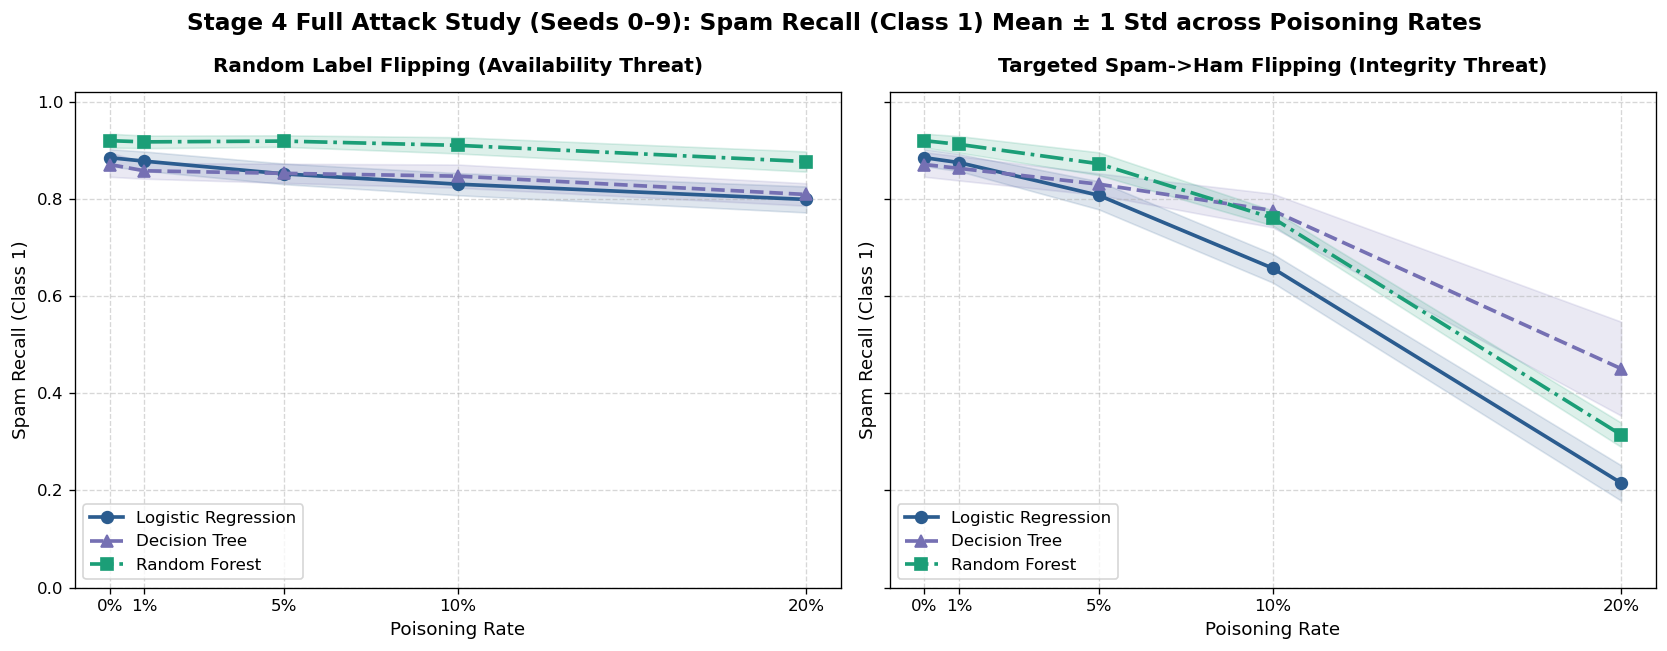

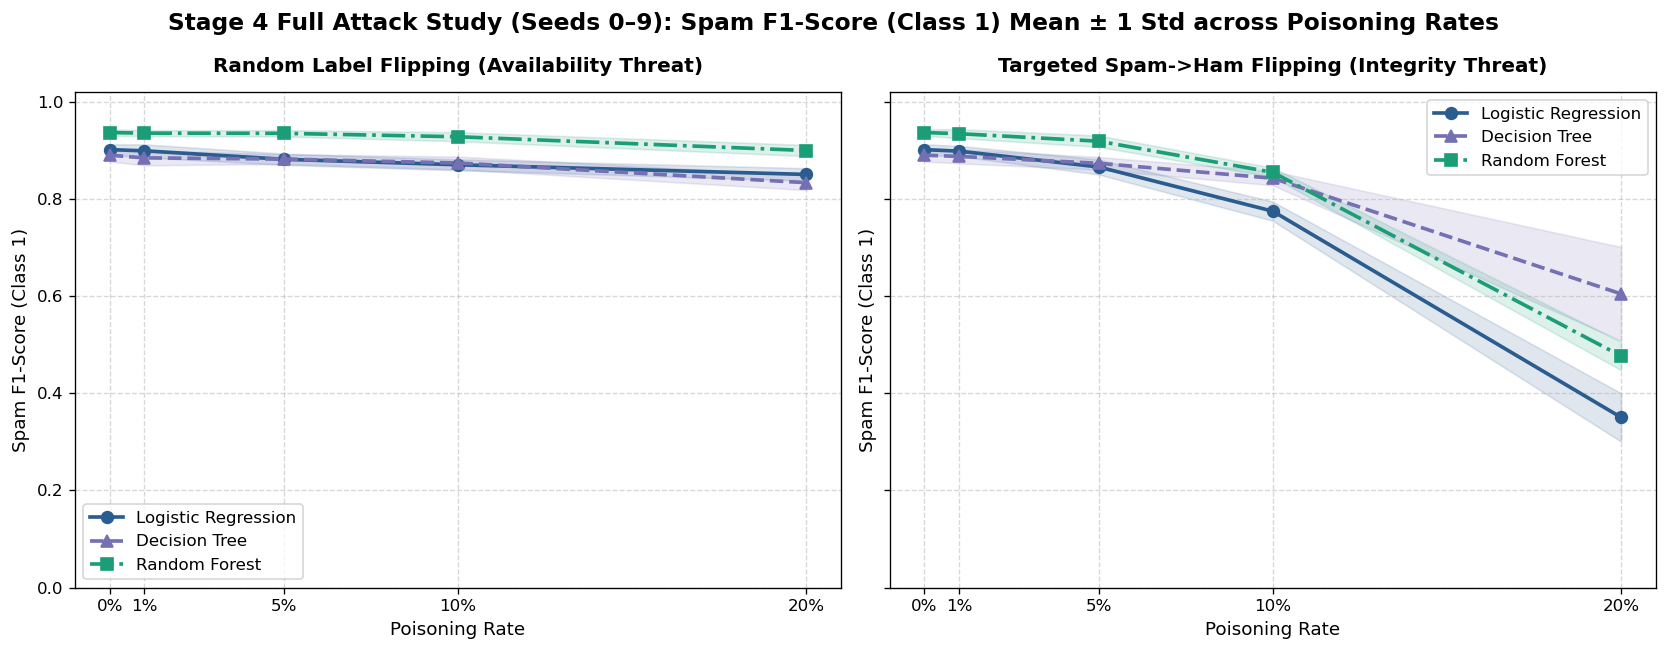

In [3]:
# Cell 3: Figure 1 (Spam Recall vs. Poisoning Rate) & Figure 2 (Spam F1 vs. Poisoning Rate)
fig1, _ = plot_pilot_learning_curves(
    attack_df, metric='spam_recall', metric_display_name='Spam Recall (Class 1)',
    save_path='../results/figures/fig1_spam_recall_vs_poison_rate.png',
    study_label='Stage 4 Full Attack Study (Seeds 0–9)'
)
plt.show()

fig2, _ = plot_pilot_learning_curves(
    attack_df, metric='spam_f1', metric_display_name='Spam F1-Score (Class 1)',
    save_path='../results/figures/fig2_spam_f1_vs_poison_rate.png',
    study_label='Stage 4 Full Attack Study (Seeds 0–9)'
)
plt.show()

## 4. Random vs. Targeted Poisoning & Model-Family Differences
Next, we directly compare availability degradation (Random Flipping) against integrity evasion (Targeted Spam$\to$Ham Flipping) in `Figure 3`, and evaluate all four metrics simultaneously across model families in `Figure 4`.

=== RANDOM VS. TARGETED DEGRADATION SUMMARY (10-SEED MEAN DROP FROM CLEAN BASELINE) ===
  attack  poison_rate               model     Spam Recall recall_drop_pp         Spam F1 f1_drop_pp  Spam Precision
  random         0.01 Logistic Regression 0.8777 ± 0.0199         -0.72% 0.8989 ± 0.0133     -0.25% 0.9214 ± 0.0123
  random         0.01       Decision Tree 0.8579 ± 0.0162         -1.29% 0.8844 ± 0.0154     -0.55% 0.9129 ± 0.0196
  random         0.01       Random Forest 0.9174 ± 0.0130         -0.25% 0.9354 ± 0.0061     -0.12% 0.9542 ± 0.0052
  random         0.05 Logistic Regression 0.8515 ± 0.0212         -3.33% 0.8815 ± 0.0115     -1.99% 0.9141 ± 0.0099
  random         0.05       Decision Tree 0.8526 ± 0.0197         -1.82% 0.8820 ± 0.0099     -0.79% 0.9139 ± 0.0163
  random         0.05       Random Forest 0.9190 ± 0.0118         -0.08% 0.9350 ± 0.0065     -0.16% 0.9516 ± 0.0068
  random         0.10 Logistic Regression 0.8303 ± 0.0228         -5.45% 0.8702 ± 0.0111     -3.12% 

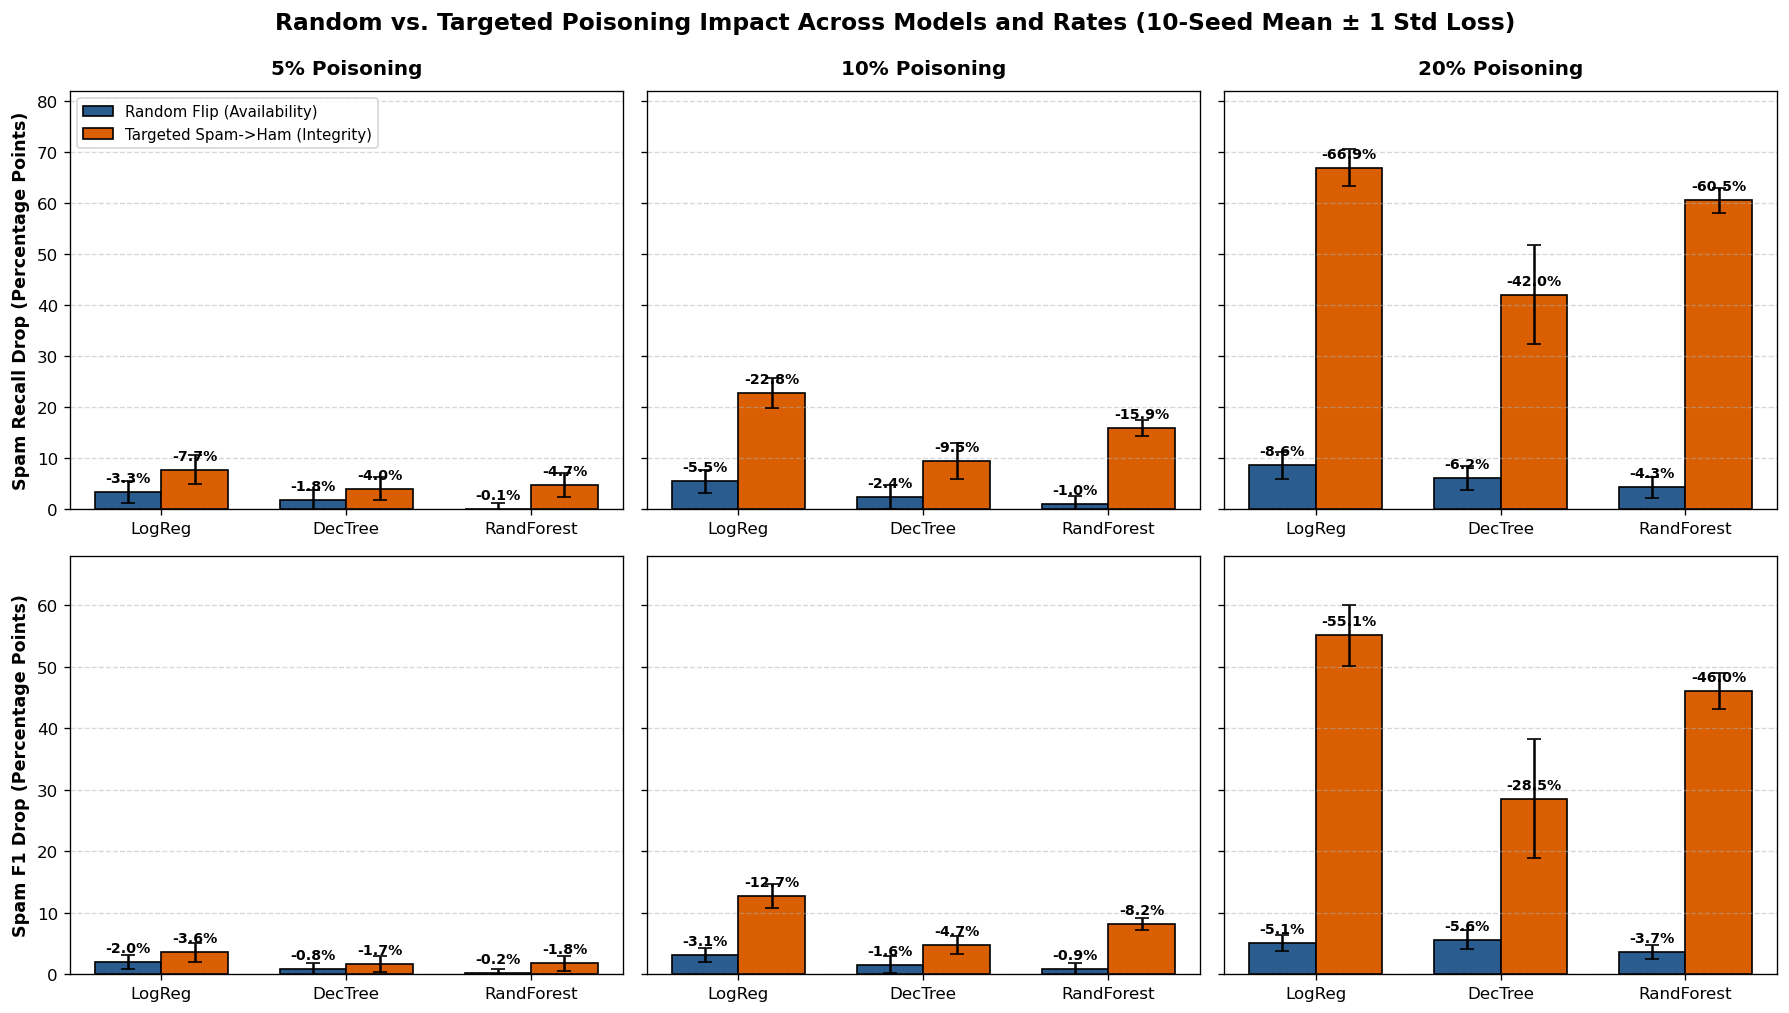

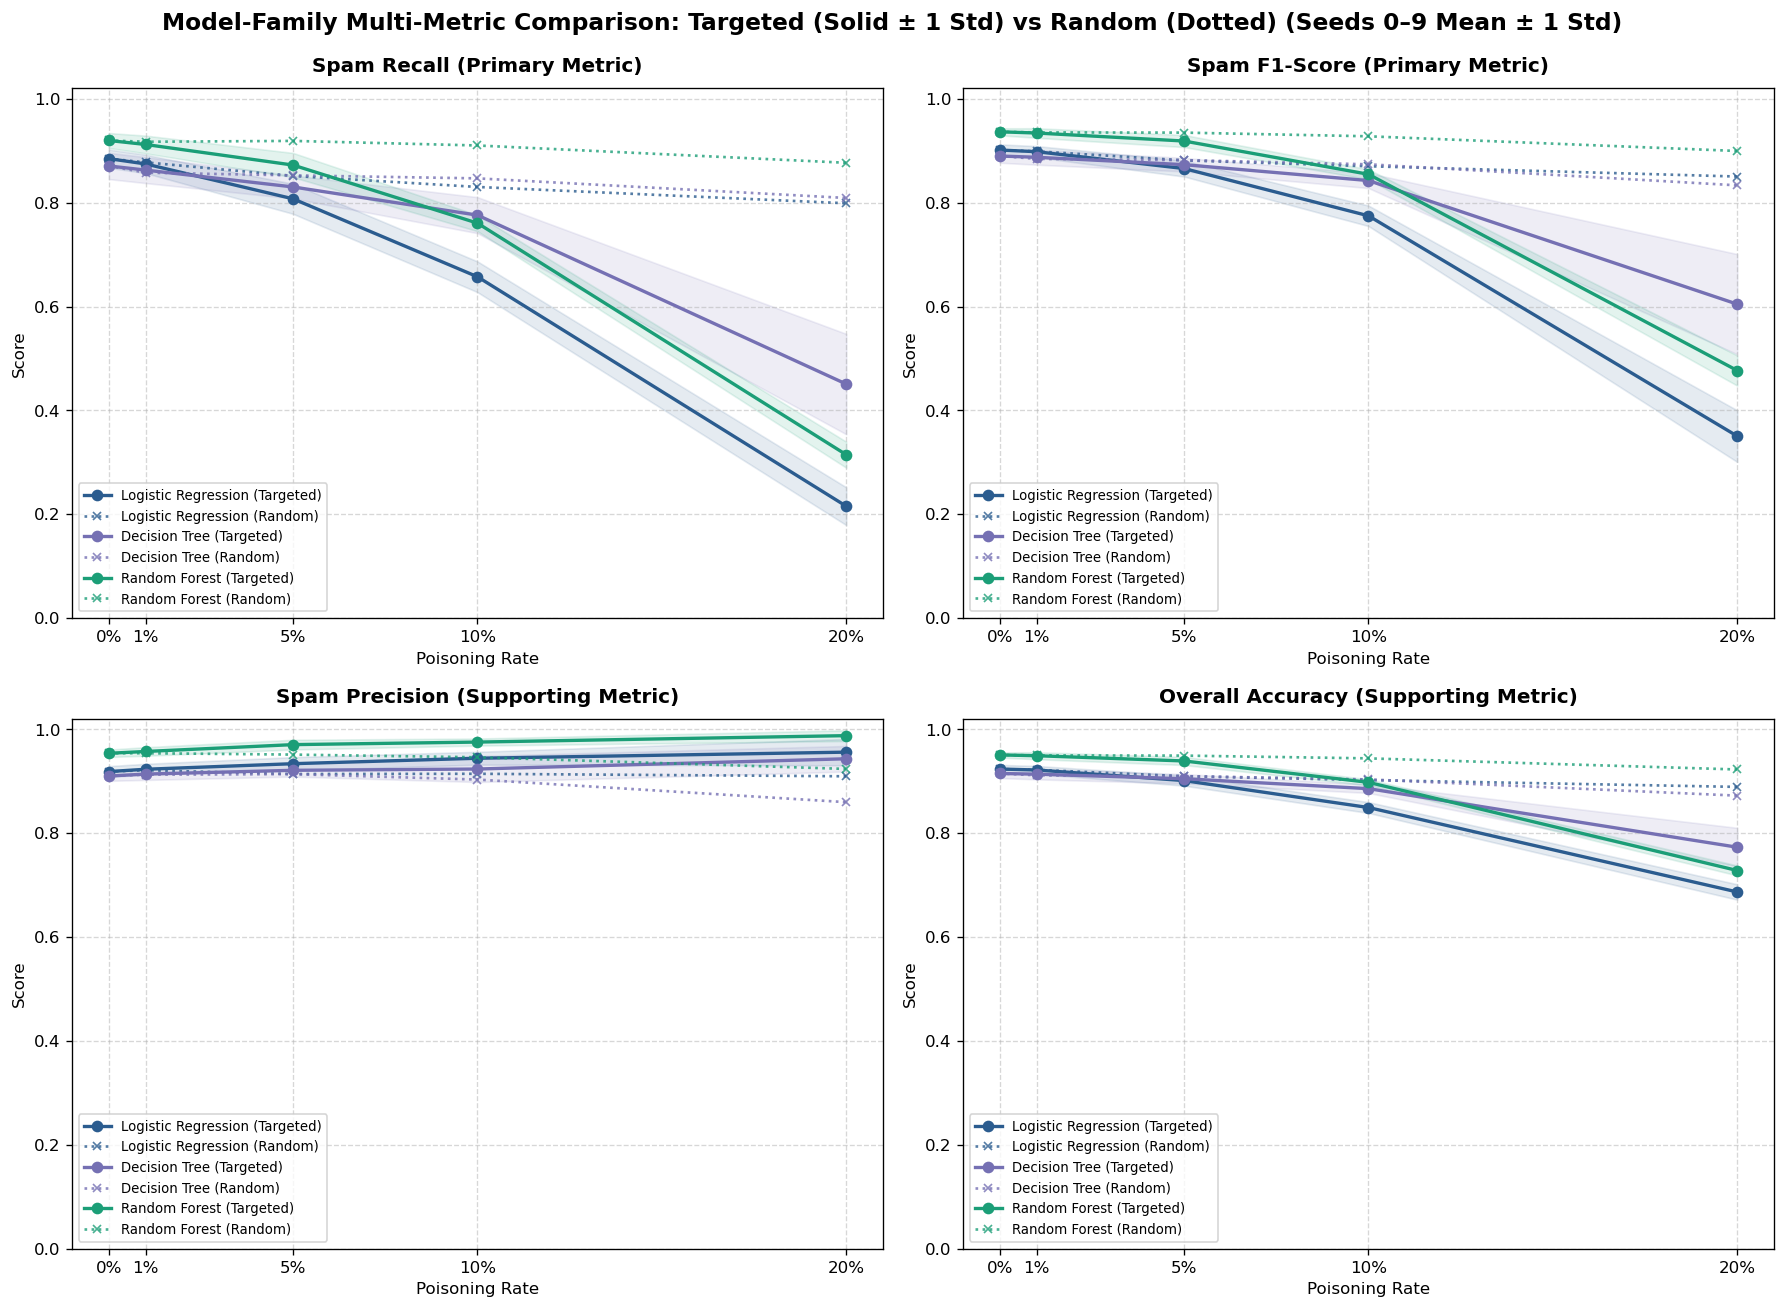

In [4]:
# Cell 4: Figure 3 (Random vs. Targeted Degradation) & Figure 4 (Model-Family Multi-Metric Grid)
deg_df = agg_df[agg_df['attack'] != 'clean'].copy()
deg_df['recall_drop_pp'] = deg_df['recall_drop'].map(lambda x: f'{x*100:+.2f}%')
deg_df['f1_drop_pp'] = deg_df['f1_drop'].map(lambda x: f'{x*100:+.2f}%')
print('=== RANDOM VS. TARGETED DEGRADATION SUMMARY (10-SEED MEAN DROP FROM CLEAN BASELINE) ===')
print(deg_df[['attack', 'poison_rate', 'model', 'Spam Recall', 'recall_drop_pp', 'Spam F1', 'f1_drop_pp', 'Spam Precision']].to_string(index=False))

fig3, _ = plot_random_vs_targeted_degradation(
    attack_df, save_path='../results/figures/fig3_random_vs_targeted_comparison.png'
)
plt.show()

fig4, _ = plot_pilot_multi_metric_grid(
    attack_df, save_path='../results/figures/fig4_model_family_differences.png',
    study_label='Seeds 0–9 Mean ± 1 Std'
)
plt.show()

## 5. Representative Confusion Matrices at 0%, 10%, and 20% Poisoning
Using the confusion matrix counts (`tn`, `fp`, `fn`, `tp`) stored directly in `results/attack_results.csv`, we display representative test-set confusion matrices (`Seed 0`, $N_{\text{test}} = 921$: $558$ Ham, $363$ Spam) alongside the 10-seed Mean $\pm$ Std confusion matrix breakdown at $0\%, 10\%,$ and $20\%$ poisoning (`Figure 5a` for Targeted Poisoning and `Figure 5b` for Random Poisoning).

=== CONFUSION MATRIX COUNTS AT 0%, 10%, AND 20% POISONING (SEED 0 & 10-SEED MEAN ± STD) ===
  Attack Poison Rate               Model  Seed0_TN  Seed0_FP  Seed0_FN  Seed0_TP     Mean_TN    Mean_FP      Mean_FN      Mean_TP
   clean          0% Logistic Regression       528        30        33       330 529.6 ± 4.0 28.4 ± 4.0   41.8 ± 6.3  321.2 ± 6.3
   clean          0%       Decision Tree       529        29        41       322 526.8 ± 3.9 31.2 ± 3.9   46.9 ± 9.2  316.1 ± 9.2
   clean          0%       Random Forest       542        16        28       335 541.9 ± 2.7 16.1 ± 2.7   29.1 ± 5.2  333.9 ± 5.2
  random         10% Logistic Regression       527        31        45       318 529.8 ± 3.6 28.2 ± 3.6   61.6 ± 8.3  301.4 ± 8.3
  random         10%       Decision Tree       522        36        46       317 525.0 ± 7.0 33.0 ± 7.0   55.6 ± 8.7  307.4 ± 8.7
  random         10%       Random Forest       539        19        26       337 539.3 ± 1.3 18.7 ± 1.3   32.6 ± 6.1  330.4 ± 6.

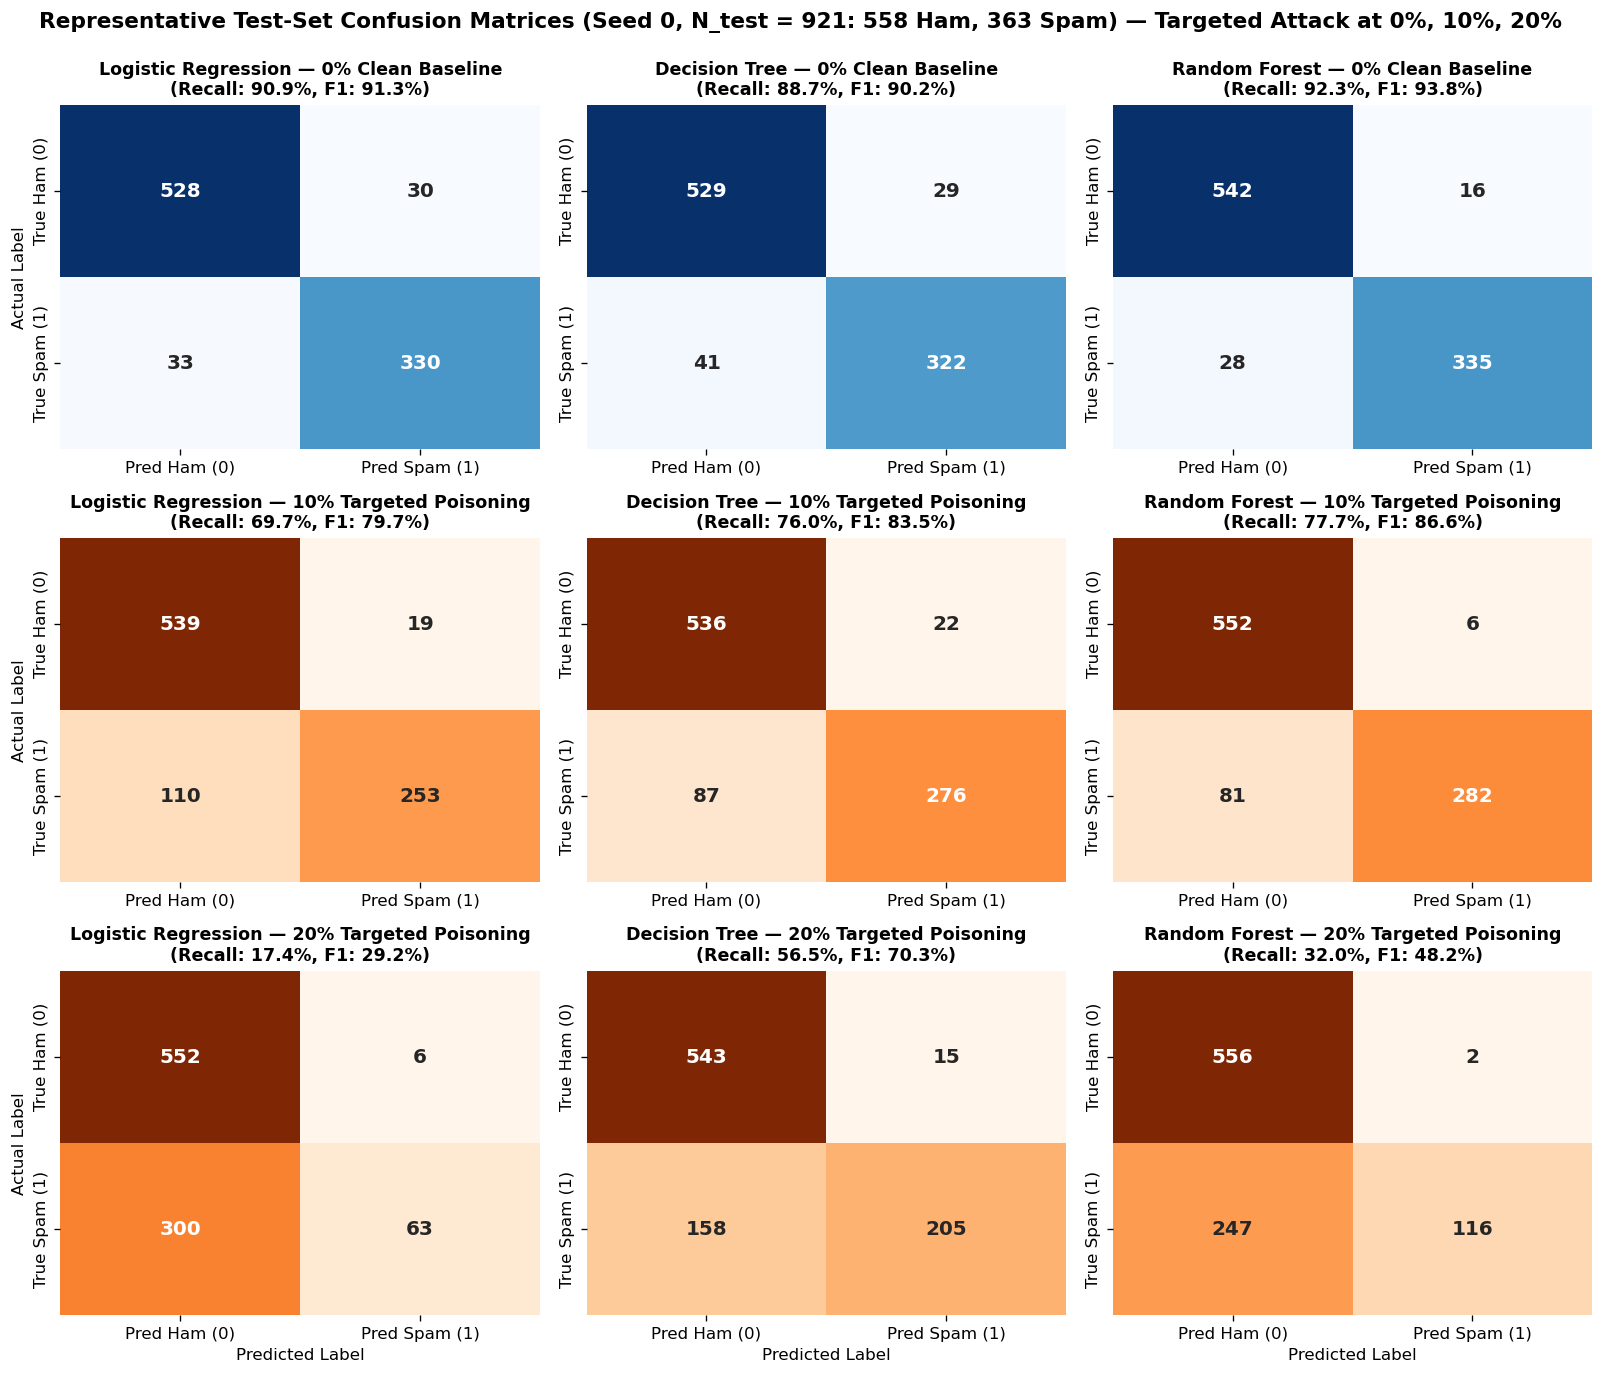

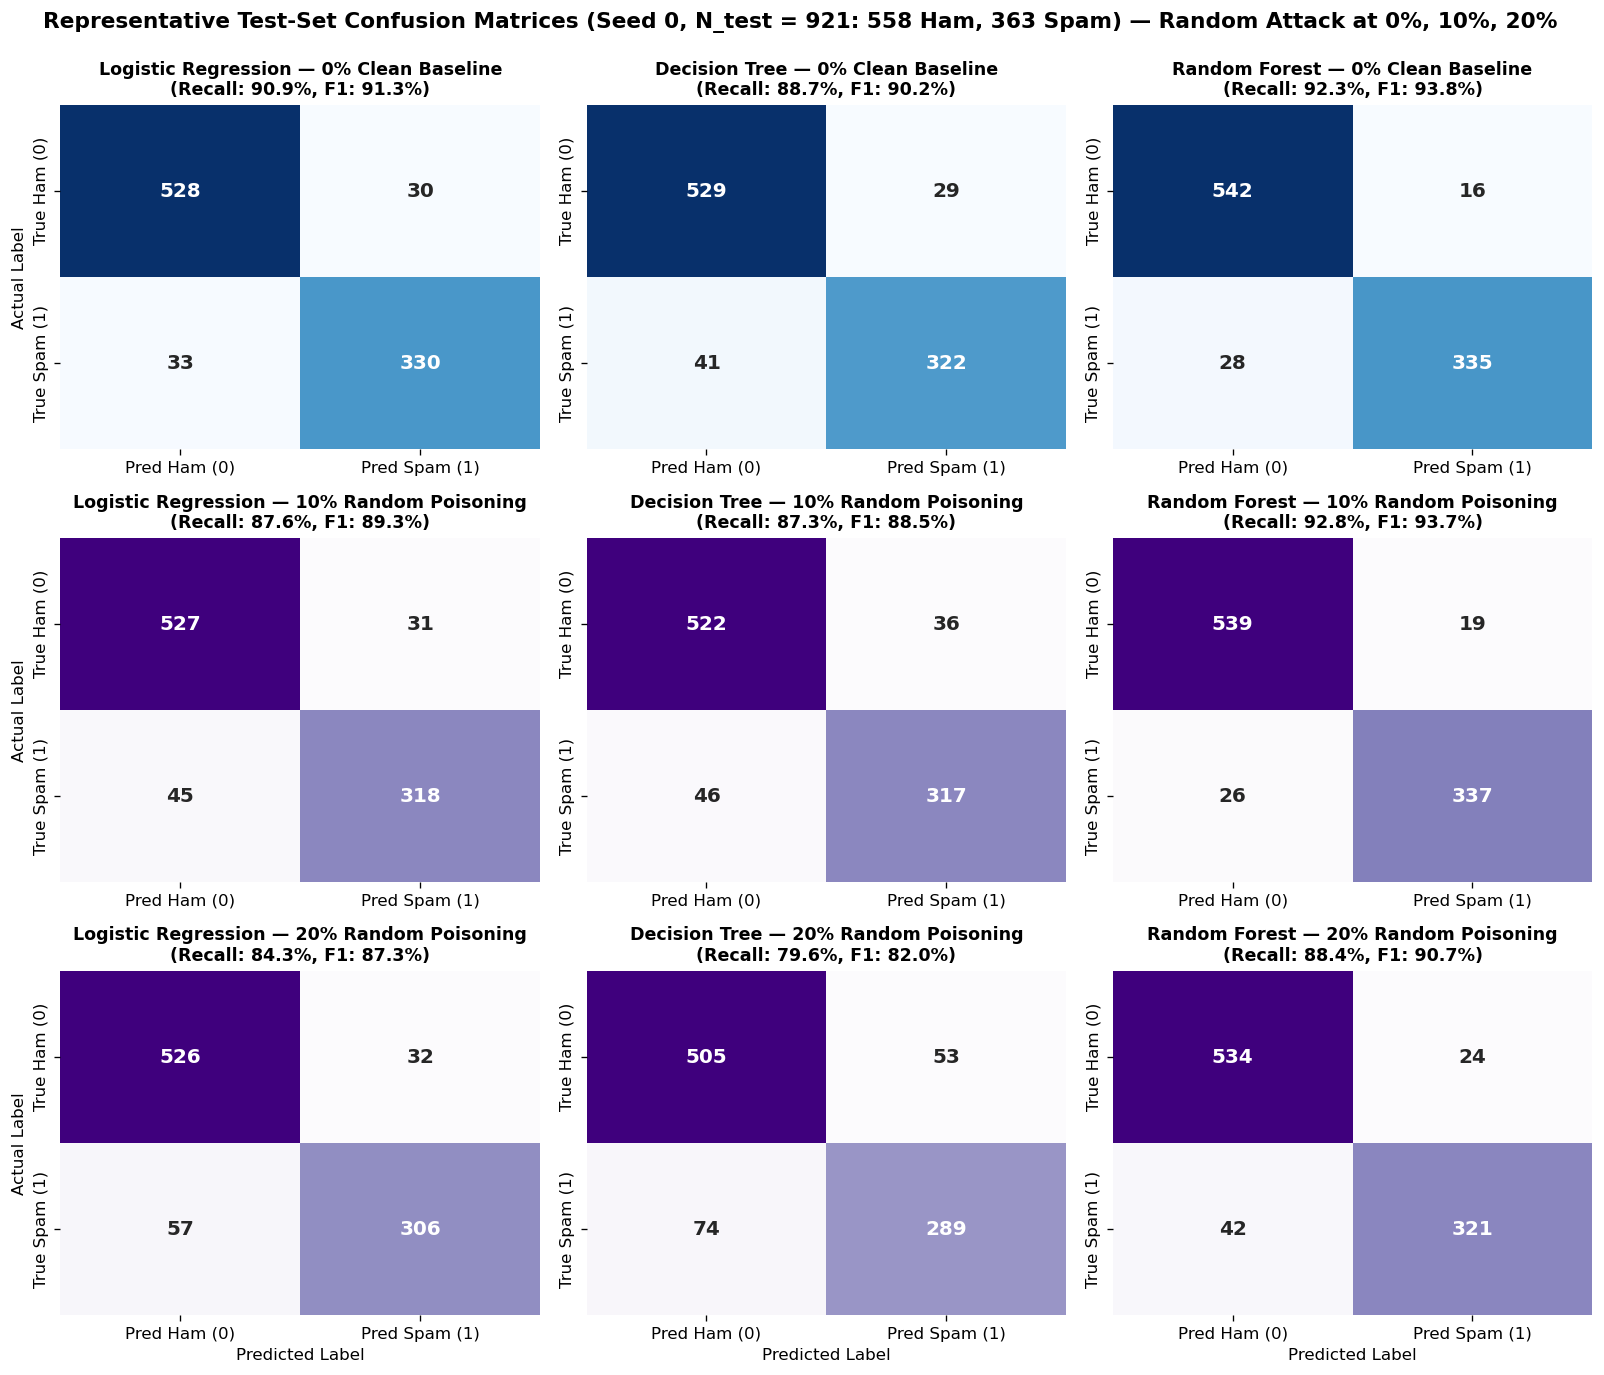

In [5]:
# Cell 5: Representative Confusion Matrices at 0%, 10%, and 20% Poisoning
cm_summary_df = pd.read_csv('../results/tables/confusion_matrices_0_10_20.csv')
print('=== CONFUSION MATRIX COUNTS AT 0%, 10%, AND 20% POISONING (SEED 0 & 10-SEED MEAN ± STD) ===')
print(cm_summary_df.to_string(index=False))

fig5a, _ = plot_representative_confusion_matrices_grid(
    attack_df, seed=0, attack='targeted',
    save_path='../results/figures/fig5_confusion_matrices_0_10_20.png'
)
plt.show()

fig5b, _ = plot_representative_confusion_matrices_grid(
    attack_df, seed=0, attack='random',
    save_path='../results/figures/fig5b_confusion_matrices_random_0_10_20.png'
)
plt.show()

## 6. Seed-Level Crossover Analysis at 10% and 20% Targeted Poisoning
We examine the 10-seed distribution of Spam Recall at $10\%$ and $20\%$ targeted poisoning (`Figure 6`) to evaluate the relationship between Decision Tree and Random Forest across all 10 random seeds.

=== 10-SEED CROSSOVER ANALYSIS: SPAM RECALL UNDER TARGETED POISONING ===
At 10% Targeted Poisoning: Decision Tree recall exceeds Random Forest in 6/10 seeds
  - Decision Tree Recall: 0.7760 ± 0.0347 (Min=0.7218, Max=0.8237)
  - Random Forest Recall: 0.7606 ± 0.0156 (Min=0.7328, Max=0.7769)

At 20% Targeted Poisoning: Decision Tree recall exceeds Random Forest in 9/10 seeds
  - Decision Tree Recall: 0.4507 ± 0.0967 (Min=0.2397, Max=0.5647)
  - Random Forest Recall: 0.3146 ± 0.0250 (Min=0.2590, Max=0.3526)

Seed-by-Seed Spam Recall at 20% Targeted Poisoning:
model  Logistic Regression  Decision Tree  Random Forest
seed                                                    
0                   0.1736         0.5647         0.3196
1                   0.2149         0.4215         0.2590
2                   0.1901         0.5455         0.3333
3                   0.1543         0.4793         0.3058
4                   0.2645         0.4325         0.3278
5                   0.2534         0.4

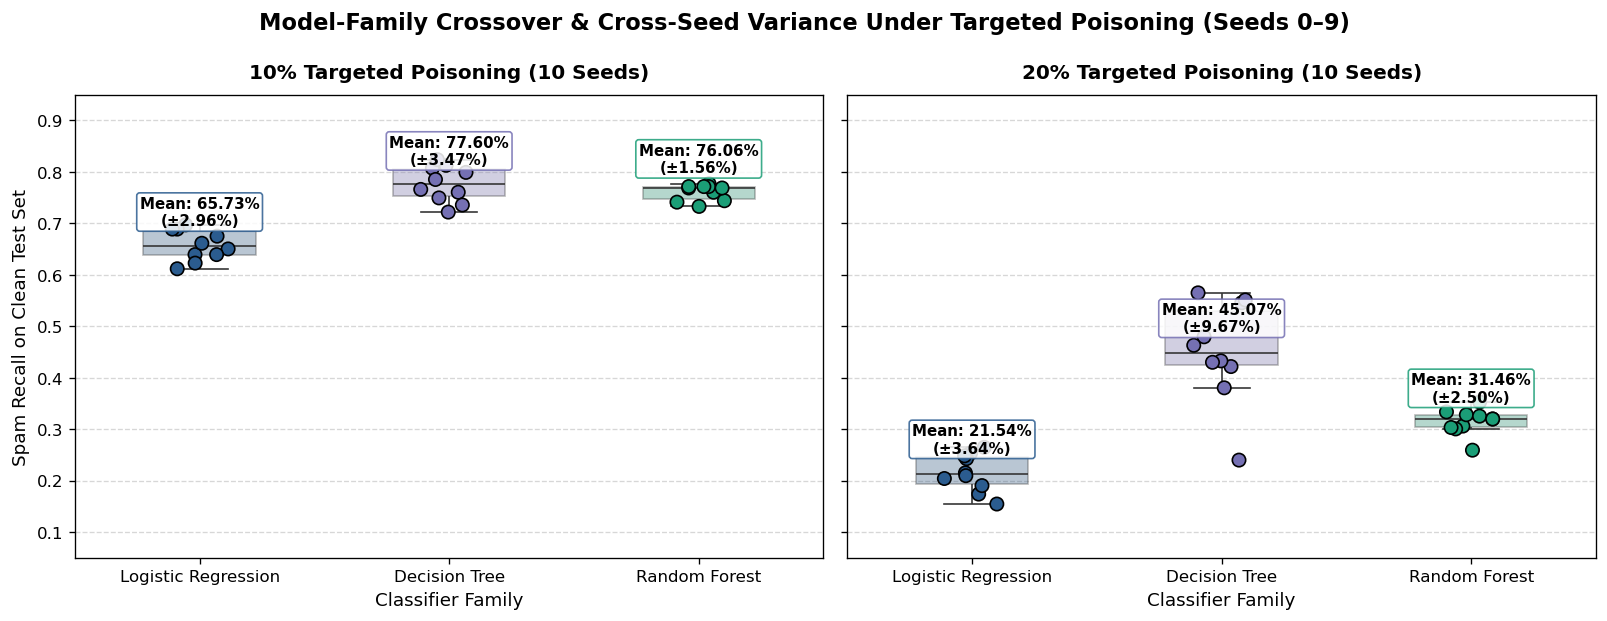

In [6]:
# Cell 6: Figure 6 — 10-Seed Crossover Distribution at 10% and 20% Targeted Poisoning
targ10_piv = attack_df[(attack_df['attack'] == 'targeted') & (np.isclose(attack_df['poison_rate'], 0.10))].pivot(index='seed', columns='model', values='spam_recall')
targ20_piv = attack_df[(attack_df['attack'] == 'targeted') & (np.isclose(attack_df['poison_rate'], 0.20))].pivot(index='seed', columns='model', values='spam_recall')
dt_beats_rf_10 = int((targ10_piv['Decision Tree'] > targ10_piv['Random Forest']).sum())
dt_beats_rf_20 = int((targ20_piv['Decision Tree'] > targ20_piv['Random Forest']).sum())

print('=== 10-SEED CROSSOVER ANALYSIS: SPAM RECALL UNDER TARGETED POISONING ===')
print(f'At 10% Targeted Poisoning: Decision Tree recall exceeds Random Forest in {dt_beats_rf_10}/10 seeds')
print(f"  - Decision Tree Recall: {targ10_piv['Decision Tree'].mean():.4f} ± {targ10_piv['Decision Tree'].std(ddof=1):.4f} (Min={targ10_piv['Decision Tree'].min():.4f}, Max={targ10_piv['Decision Tree'].max():.4f})")
print(f"  - Random Forest Recall: {targ10_piv['Random Forest'].mean():.4f} ± {targ10_piv['Random Forest'].std(ddof=1):.4f} (Min={targ10_piv['Random Forest'].min():.4f}, Max={targ10_piv['Random Forest'].max():.4f})\n")
print(f'At 20% Targeted Poisoning: Decision Tree recall exceeds Random Forest in {dt_beats_rf_20}/10 seeds')
print(f"  - Decision Tree Recall: {targ20_piv['Decision Tree'].mean():.4f} ± {targ20_piv['Decision Tree'].std(ddof=1):.4f} (Min={targ20_piv['Decision Tree'].min():.4f}, Max={targ20_piv['Decision Tree'].max():.4f})")
print(f"  - Random Forest Recall: {targ20_piv['Random Forest'].mean():.4f} ± {targ20_piv['Random Forest'].std(ddof=1):.4f} (Min={targ20_piv['Random Forest'].min():.4f}, Max={targ20_piv['Random Forest'].max():.4f})\n")
print('Seed-by-Seed Spam Recall at 20% Targeted Poisoning:')
print(targ20_piv[['Logistic Regression', 'Decision Tree', 'Random Forest']].round(4).to_string())

fig6, _ = plot_seed_crossover_distributions(
    attack_df, save_path='../results/figures/fig6_seed_variance_and_crossover.png'
)
plt.show()

## 7. Evaluating Stage 3 Hypotheses: Direct Observations vs. Possible Explanations

### Hypothesis 1: Targeted Spam-to-Ham Poisoning Degrades Spam Recall Much More Severely Than Random Flipping
- **Status:** **Strongly Supported across all 10 seeds and all three model families.**
- **Direct Empirical Observations:**
  1. Under **20% random label flipping** ($736$ bidirectional flips), 10-seed mean spam recall declines by $-8.60$ percentage points for Logistic Regression ($88.48\% \to 79.89\% \pm 2.68\%$), $-6.17$ percentage points for Decision Tree ($87.08\% \to 80.91\% \pm 2.31\%$), and $-4.30$ percentage points for Random Forest ($91.98\% \to 87.69\% \pm 2.08\%$). Both false positives and false negatives increase moderately (e.g., on Seed 0, Random Forest FP rises from $16 \to 22$ and FN rises from $28 \to 42$; `Figure 5b`).
  2. Under **20% targeted spam-to-ham flipping** ($736$ spam instances flipped to ham), 10-seed mean spam recall collapses by **$-66.94$ percentage points** for Logistic Regression ($88.48\% \to 21.54\% \pm 3.64\%$), **$-42.01$ percentage points** for Decision Tree ($87.08\% \to 45.07\% \pm 9.67\%$), and **$-60.52$ percentage points** for Random Forest ($91.98\% \to 31.46\% \pm 2.50\%$). Simultaneously, 10-seed mean spam precision remains high ($95.63\%$ for Logistic Regression, $94.35\%$ for Decision Tree, and $98.81\%$ for Random Forest), and false positives drop near zero (`Figure 4`, `Figure 5a`).
- **Possible Mechanistic Explanation:** Because targeted poisoning relabels $736$ of the $1,450$ training spam instances ($50.8\%$) as ham while leaving all $2,230$ training ham labels intact, the apparent training prior shifts from $39.4\%$ spam to $19.4\%$ spam, and the empirical risk minimizer is heavily penalized for predicting class $1$ inside the poisoned spam region.

### Hypothesis 2: Model Families Respond Differently to Label Poisoning (and Exhibit a Crossover Under High Targeted Poisoning)
- **Status:** **Supported for general random-noise resilience, with an important empirical nuance (crossover) under 10%–20% targeted poisoning.**
- **Direct Empirical Observations:**
  1. On clean data ($0\%$) and across all random poisoning rates ($1\%$–$20\%$), Random Forest achieves the highest accuracy, spam precision, spam recall, and spam F1 (`Figure 1`, `Figure 2`).
  2. Under targeted poisoning, Logistic Regression degrades fastest at every rate $\ge 5\%$, dropping to $65.73\% \pm 2.96\%$ recall at $10\%$ and $21.54\% \pm 3.64\%$ at $20\%$.
  3. **The Decision Tree vs. Random Forest Crossover:** At $10\%$ targeted poisoning, Decision Tree achieves a slightly higher 10-seed mean spam recall ($77.60\% \pm 3.47\%$) than Random Forest ($76.06\% \pm 1.56\%$, beating Random Forest in $7/10$ seeds), though Random Forest still maintains a higher spam F1 ($85.47\%$ vs. $84.26\%$) due to higher precision ($97.57\%$ vs. $92.38\%$). At **$20\%$ targeted poisoning**, Decision Tree outperforms Random Forest in **both** spam recall ($45.07\% \pm 9.67\%$ vs. $31.46\% \pm 2.50\%$, higher in $9/10$ seeds; only in Seed 6 does Decision Tree drop to $29.75\%$ vs. Random Forest $31.68\%$) and spam F1 ($60.46\% \pm 9.64\%$ vs. $47.67\% \pm 2.91\%$). However, Decision Tree exhibits nearly $4\times$ larger cross-seed recall standard deviation ($\pm 9.67\%$ vs. $\pm 2.50\%$; `Figure 6`).
- **Possible Mechanistic Interpretation (Not Yet Confirmed):** A plausible interpretation is that when $50.8\%$ of training spam labels are flipped to $0$, bootstrap aggregation and random feature subsampling across $200$ trees cause the ensemble's average predicted spam probability to fall below the $0.5$ threshold across most of the spam manifold. In contrast, a single depth-8 greedy tree splits on the highest-gain uncorrupted coordinate thresholds and may preserve localized spam-majority leaves—at the cost of high sensitivity to which specific spam examples are flipped in each seed (explaining the $\pm 9.67\%$ standard deviation and Seed 7 drop). **Confirming this interpretation as a causal mechanism would require direct inspection of Random Forest tree-vote distributions, predicted probabilities, or leaf-level impurity statistics.**